# Maturidade tecnológica e troca de informações nos estabelecimentos de saúde brasileiros
### Seminário de Mineração de Dados — TIC Saúde 2025 (Cetic.br | NIC.br)

**Autor:** Guilherme Aparecido Tavares da Silva

**Pergunta-alvo.** *Quais perfis de maturidade tecnológica e de troca eletrônica de informações emergem entre os estabelecimentos de saúde brasileiros, quão estáveis são esses perfis e a que características institucionais e territoriais eles estão associados?*

**Tarefa de mineração.** Agrupamento (clustering) exploratório, com avaliação interna, de estabilidade e validação externa.

**Que evidência responde à pergunta.**
1. grupos que se repetem sob reamostragem e sob mudanças razoáveis de método (estabilidade);
2. grupos interpretáveis nas variáveis originais (não apenas no rótulo);
3. grupos que se diferenciam em variáveis **não usadas** para formá-los (validação externa: integração sistema-a-sistema e RNDS).

**Roteiro do notebook:** 1) dados e rastreabilidade · 2) desenho amostral e validação contra as tabelas oficiais · 3) qualidade dos dados · 4) atributos · 5) análise exploratória · 6) hipóteses H1 e H2 · 7) clustering · 8) robustez · 9) caracterização e validação externa · 10) respostas e limitações.

## 0. Ambiente e reprodutibilidade

In [1]:
%pip -q install kmodes

In [2]:
import os, sys, glob, zipfile, warnings, urllib.request, urllib.parse
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
import sklearn, scipy, kmodes
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA
from kmodes.kmodes import KModes
from scipy.optimize import linear_sum_assignment
warnings.filterwarnings('ignore')

SEED = 42
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', None)
for m in (np, pd, matplotlib, sklearn, scipy):
    print(f'{m.__name__:12s} {m.__version__}')
print('python      ', sys.version.split()[0], '| semente =', SEED)

# Estilo dos gráficos: grade discreta, uma cor por perfil (ordem fixa)
INK, MUTED, GRID = '#0b0b0b', '#898781', '#e1e0d9'
COR = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']          # perfis A, B, C, D
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': MUTED,
    'ytick.color': '#52514e', 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .6, 'axes.axisbelow': True,
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.titlelocation': 'left', 'legend.frameon': False})
os.makedirs('outputs/figures', exist_ok=True); os.makedirs('outputs/tables', exist_ok=True)
def salvar(nome): plt.savefig(f'outputs/figures/{nome}.png', bbox_inches='tight')

numpy        2.5.3
pandas       3.0.5
matplotlib   3.11.2
sklearn      1.9.1
scipy        1.18.1
python       3.13.18 | semente = 42


## 1. Dados e rastreabilidade

| Item | Registro |
|---|---|
| Fonte | Pesquisa **TIC Saúde 2025 — Estabelecimentos**, Cetic.br / NIC.br / CGI.br |
| Página | https://www.cetic.br/pt/arquivos/saude/2025/estabelecimentos/ |
| Arquivo | `tic_saude_2025_estabelecimentos_pós_cec_base_de_microdados_v1.0.csv` (microdados **com tratamento de confidencialidade**, v1.0) |
| Download | 15/11/2026 |
| Licença | Creative Commons Atribuição 4.0 (CC BY 4.0) — uso permitido com citação da fonte |
| Dicionário | v1.0 dentro do ZIP (a página lista também uma v1.1) |
| Coleta | fevereiro a novembro de 2025; CATI (telefone), com opção de autopreenchimento Web |
| Respondente | gestor de TI ou, na falta, gestor principal do estabelecimento |

A célula abaixo procura o CSV localmente; se não achar, baixa o ZIP oficial; se a rede falhar no Colab, pede o upload.

In [3]:
ZIP_URL = 'https://cetic.br/media/microdados/1072/tic_saude_2025_estabelecimentos_pós_cec_base_de_microdados.zip'
PADRAO  = '*base_de_microdados_v1.0.csv'

def localizar_csv():
    if os.environ.get('TIC_CSV') and os.path.exists(os.environ['TIC_CSV']):
        return os.environ['TIC_CSV']
    achados = glob.glob('**/' + PADRAO, recursive=True) + glob.glob('../**/' + PADRAO, recursive=True)
    if achados: return achados[0]
    try:                                             # download do ZIP oficial
        url = urllib.parse.quote(ZIP_URL, safe=':/')
        urllib.request.urlretrieve(url, 'tic_saude_2025.zip')
        zipfile.ZipFile('tic_saude_2025.zip').extractall('data_raw')
    except Exception as e:
        print('Download automático falhou:', e)
        try:
            from google.colab import files          # upload manual (CSV ou ZIP)
            for nome in files.upload():
                if nome.lower().endswith('.zip'): zipfile.ZipFile(nome).extractall('data_raw')
        except ImportError:
            pass
    achados = glob.glob('**/' + PADRAO, recursive=True) + glob.glob('../**/' + PADRAO, recursive=True)
    if not achados: raise FileNotFoundError('Coloque o CSV de microdados na pasta do notebook.')
    return achados[0]

CAMINHO = localizar_csv()
with open(CAMINHO, 'rb') as f: amostra = f.read(400)
print('Arquivo :', os.path.basename(CAMINHO))
print('Início  :', amostra[:90])

Arquivo : base_de_microdados_v1.0.csv
Início  : b'"ID_QUEST";"B1_A_1";"B1_A_2";"B1_A_3";"B1_B";"B2";"B3_1";"B3_2";"B3_3";"B3_4";"B3_5";"B3_6'


O início do arquivo mostra o delimitador `;` e campos entre aspas. O peso amostral usa vírgula decimal. Lemos com essas opções e conferimos.

In [4]:
df = pd.read_csv(CAMINHO, sep=';', decimal=',', encoding='latin-1')
REPS = [c for c in df.columns if c.startswith('REP')]
print('Dimensões:', df.shape, '| réplicas de peso:', len(REPS))
print('ID_QUEST único:', df['ID_QUEST'].is_unique, '| linhas duplicadas:', int(df.duplicated().sum()))
print('Valores nulos (NaN):', int(df.isna().sum().sum()))
print('Tipos:', df.dtypes.value_counts().to_dict())
df[['ID_QUEST', 'COD_REGIAO', 'TIPO_CETIC_TAB', 'COD_ESFADM_BASE', 'UBS', 'B2', 'C1_1', 'C8', 'C9', 'PESO']].head()

Dimensões: (3261, 348) | réplicas de peso: 200
ID_QUEST único: True | linhas duplicadas: 0
Valores nulos (NaN): 0
Tipos: {dtype('int64'): 347, dtype('float64'): 1}


,ID_QUEST,COD_REGIAO,TIPO_CETIC_TAB,COD_ESFADM_BASE,UBS,B2,C1_1,C8,C9,PESO
0,33666645,2,1,2,2,1,1,0,97,1.783707
1,33666646,2,1,1,2,1,1,0,0,6.530773
2,33666647,2,1,2,2,1,1,1,1,5.787651
3,33804453,2,1,1,2,1,1,0,0,6.530773
4,33820944,2,0,1,2,1,1,1,97,20.219768


## 2. Desenho amostral, população e validação

**População-alvo.** Estabelecimentos públicos e privados cadastrados no CNES, com CNPJ próprio ou de mantenedora, instalações físicas para ações de saúde e ao menos um médico ou enfermeiro. Ficam **fora**: consultórios isolados, pessoas físicas, unidades móveis, farmácias, estabelecimentos de campanha e órgãos de gestão.

**Unidade de análise.** O estabelecimento de saúde (uma linha = um estabelecimento; não há medidas repetidas).

**Plano amostral.** Amostra estratificada (UF × esfera administrativa × tipo de estabelecimento), sorteio aleatório simples dentro do estrato. Pesos = inverso da probabilidade de seleção, corrigidos por não resposta e calibrados aos totais do cadastro.

**Não resposta.** Foram abordados 15.750 estabelecimentos e 3.270 concluíram a entrevista (**taxa de resposta de 21%**). Os pesos corrigem a não resposta apenas nas variáveis do cadastro; se quem respondeu for mais digitalizado do que quem não respondeu, as estimativas ficam otimistas. Essa é a principal ameaça à representatividade.

**Domínios de divulgação.** Esfera administrativa, região, tipo de estabelecimento, UBS (a base pública traz essas quatro; UF e capital/interior não estão nos microdados).

In [5]:
ROT = {'COD_REGIAO': {1: 'Norte', 2: 'Nordeste', 3: 'Sudeste', 4: 'Sul', 5: 'Centro-Oeste'},
       'TIPO_CETIC_TAB': {0: 'Sem internação', 1: 'Com internação', 3: 'SADT'},
       'COD_ESFADM_BASE': {1: 'Público', 2: 'Privado'}, 'UBS': {1: 'UBS', 2: 'Não UBS'}}
print(f"Amostra: {len(df)} estabelecimentos | soma dos pesos (população estimada): {df['PESO'].sum():,.0f}")
print(f"Peso: mín {df['PESO'].min():.1f} | mediana {df['PESO'].median():.1f} | máx {df['PESO'].max():.1f}\n")
for v, r in ROT.items():
    t = df.groupby(df[v].map(r)).agg(n_amostra=('PESO', 'size'), populacao=('PESO', 'sum'))
    t['% amostra'] = (100 * t['n_amostra'] / len(df)).round(1); t['% população'] = (100 * t['populacao'] / df['PESO'].sum()).round(1)
    print(t.round(0).to_string(), '\n')

Amostra: 3261 estabelecimentos | soma dos pesos (população estimada): 129,728
Peso: mín 1.0 | mediana 25.7 | máx 788.8

              n_amostra  populacao  % amostra  % população
COD_REGIAO                                                
Centro-Oeste        435    11906.0       13.0          9.0
Nordeste            813    35895.0       25.0         28.0
Norte               281     8513.0        9.0          7.0
Sudeste             995    50696.0       30.0         39.0
Sul                 737    22718.0       23.0         18.0 

                n_amostra  populacao  % amostra  % população
TIPO_CETIC_TAB                                              
Com internação        747     8175.0       23.0          6.0
SADT                  431    15169.0       13.0         12.0
Sem internação       2083   106384.0       64.0         82.0 

                 n_amostra  populacao  % amostra  % população
COD_ESFADM_BASE                                              
Privado               1771    7001

A amostra **sobre-representa** hospitais (com internação: 23% da amostra, 6% da população) e sub-representa UBS. Por isso toda estatística descritiva deste notebook é **ponderada**.

### 2.1 Funções de estimação ponderada

Os microdados trazem 200 réplicas (`REP1`…`REP200`), que são multiplicadores do peso. A incerteza é estimada recalculando cada estatística com `PESO × REPr` e medindo a dispersão em torno da estimativa pontual.

In [6]:
FATOR_MOE = 1.0      # ajustado na seção 2.2, depois da comparação com as margens oficiais

def prop(ind, w):
    """Proporção ponderada (%) de um indicador 0/1."""
    return 100 * np.sum(ind * w) / np.sum(w)

def est_ic(base, func):
    """Estimativa e margem de erro (95%) por réplicas. func(d, w) -> número."""
    w = base['PESO'].values; theta = func(base, w)
    R = base[REPS].values
    rep = np.array([func(base, w * R[:, j]) for j in range(R.shape[1])])
    return theta, FATOR_MOE * 1.96 * np.sqrt(np.mean((rep - theta) ** 2))

def prop_ic(base, ind):
    ind = np.asarray(ind, dtype=float)
    return est_ic(base, lambda d, w: prop(ind, w))

### 2.2 Validação contra as tabelas oficiais
As proporções abaixo são comparadas com os valores publicados (planilha `tabela_proporcao_v1.0.xlsx`), no mesmo universo: estabelecimentos que usaram Internet nos últimos 12 meses.

In [7]:
u = df[df['B2'] == 1].reset_index(drop=True)           # universo dos módulos B–H
oficiais = [('B0  Sistema eletrônico de registro (C1_1)', 'C1_1', 92.290),
            ('B9  Sistema troca dados com outros sistemas (C8)', 'C8', 27.016),
            ('B10 Integrado à RNDS (C9)', 'C9', 44.170),
            ('B6  Envia/recebe informações clínicas (C7_1)', 'C7_1', 37.618),
            ('B6  Envia/recebe encaminhamentos (C7_2)', 'C7_2', 44.304),
            ('B6  Envia/recebe exames de imagem (C7_6)', 'C7_6', 28.552)]
val = pd.DataFrame([(n, round(prop((u[v] == 1).values, u['PESO'].values), 3), o) for n, v, o in oficiais],
                   columns=['Indicador', 'Calculado (%)', 'Oficial (%)'])
val['Diferença'] = (val['Calculado (%)'] - val['Oficial (%)']).round(3)
print(f'Universo: {len(u)} estabelecimentos com Internet (população estimada {u["PESO"].sum():,.0f})')
val

Universo: 3234 estabelecimentos com Internet (população estimada 127,998)


,Indicador,Calculado (%),Oficial (%),Diferença
0,B0 Sistema eletrônico de registro (C1_1),92.290,92.290,0.000
1,B9 Sistema troca dados com outros sistemas (C8),27.016,27.016,0.000
2,B10 Integrado à RNDS (C9),44.174,44.170,0.004
3,B6 Envia/recebe informações clínicas (C7_1),37.618,37.618,0.000
4,B6 Envia/recebe encaminhamentos (C7_2),44.304,44.304,0.000
5,B6 Envia/recebe exames de imagem (C7_6),28.552,28.552,0.000


In [8]:
# Margem de erro: réplicas x tabela oficial (indicador B9 "Sim")
moe_of = {'Total': 3.013, 'Público': 5.948, 'Privado': 2.405, 'Sem internação': 3.583,
          'Com internação': 4.526, 'SADT': 5.173, 'UBS': 7.789, 'Não UBS': 2.253}
filtros = {'Total': u.index >= 0, 'Público': u['COD_ESFADM_BASE'] == 1, 'Privado': u['COD_ESFADM_BASE'] == 2,
           'Sem internação': u['TIPO_CETIC_TAB'] == 0, 'Com internação': u['TIPO_CETIC_TAB'] == 1,
           'SADT': u['TIPO_CETIC_TAB'] == 3, 'UBS': u['UBS'] == 1, 'Não UBS': u['UBS'] == 2}
lin = []
for nome, f in filtros.items():
    b = u[np.asarray(f)]; p, m = prop_ic(b, b['C8'] == 1)
    lin.append((nome, round(p, 1), round(m, 2), moe_of[nome], round(m / moe_of[nome], 2)))
moe = pd.DataFrame(lin, columns=['Recorte', 'C8 Sim (%)', 'Margem réplicas', 'Margem oficial', 'Razão'])
RAZAO_MOE = moe['Razão'].mean()
FATOR_MOE = 1 / RAZAO_MOE          # daqui em diante as margens são alinhadas às oficiais (mais conservadoras)
print(f'Razão média réplicas/oficial: {RAZAO_MOE:.2f}  ->  fator de correção aplicado às margens: {FATOR_MOE:.2f}')
moe

Razão média réplicas/oficial: 0.86  ->  fator de correção aplicado às margens: 1.16


,Recorte,C8 Sim (%),Margem réplicas,Margem oficial,Razão
0,Total,27.0,2.60,3.013,0.86
1,Público,43.0,5.11,5.948,0.86
2,Privado,13.7,2.08,2.405,0.86
3,Sem internação,27.9,3.08,3.583,0.86
4,Com internação,28.9,3.88,4.526,0.86
5,SADT,19.9,4.48,5.173,0.87
6,UBS,45.9,6.69,7.789,0.86
7,Não UBS,17.6,1.95,2.253,0.87


**Leitura.**
- As estimativas pontuais reproduzem as tabelas oficiais até a terceira casa decimal. Leitura do arquivo, universo e pesos estão corretos.
- As margens de erro calculadas pelas réplicas ficam sistematicamente em **0,86** das margens oficiais (a razão é quase idêntica nos oito recortes). A documentação não descreve as réplicas, então a causa não pôde ser confirmada. Decisão: **multiplicar as margens por 1/0,86 ≈ 1,16** no restante do notebook, o que as iguala às oficiais nos casos conferidos e é a escolha conservadora.
- A base de microdados tem 3.261 registros; o relatório de coleta cita 3.270 entrevistas. A diferença de 9 registros é compatível com o tratamento de confidencialidade, mas não está documentada.

## 3. Qualidade dos dados

Não há `NaN` no arquivo: a ausência é sempre um **código**. É preciso separar cinco situações:

| Código | Significado | Tratamento adotado |
|---|---|---|
| 0 | Não | 0 |
| 1 | Sim | 1 |
| 97 | Não sabe | 0 no indicador principal ("capacidade **não afirmada** pelo gestor"); analisado à parte |
| 98 | Não respondeu | idem |
| 99 / 999999 | Não se aplica (pergunta não feita por filtro) | fora do universo ou 0, conforme o caso, sempre declarado |

Essa é a mesma convenção das tabelas oficiais, que publicam o percentual de "Sim" sobre o total do universo.

In [9]:
META = ['ID_QUEST', 'PESO'] + REPS
vars_q = [c for c in df.columns if c not in META]
qual = pd.DataFrame({'%_nao_sabe': [100 * (u[c] == 97).mean() for c in vars_q],
                     '%_nao_resp': [100 * (u[c] == 98).mean() for c in vars_q],
                     '%_nao_se_aplica': [100 * (u[c].isin([99, 999999])).mean() for c in vars_q],
                     'n_categorias': [u[c].nunique() for c in vars_q]}, index=vars_q).round(1)
qual.to_csv('outputs/tables/qualidade_variaveis.csv')
print('Variáveis com mais "não sabe" (universo: com Internet):')
print(qual.sort_values('%_nao_sabe', ascending=False).head(10).to_string())
print('\nVariáveis com universo condicional (mais de 5% "não se aplica"):')
print(qual[qual['%_nao_se_aplica'] > 5].index.tolist())

Variáveis com mais "não sabe" (universo: com Internet):
        %_nao_sabe  %_nao_resp  %_nao_se_aplica  n_categorias
B5_1          30.7         0.6              0.0            10
H3_1A         24.9         0.5              0.4             5
H1A           24.1         0.5              0.4             5
C9            23.3         0.0              8.4             4
C9A_G         21.4         0.3              0.4             5
C9A_F         17.1         0.4              0.4             5
B18_4         13.2         0.2              0.4             5
C8A           10.5         0.2              0.4             5
B18_2         10.3         0.4              0.4             5
C9A_H1        10.0         0.3              0.4             5

Variáveis com universo condicional (mais de 5% "não se aplica"):
['B8_4A', 'C4A_1', 'C4A_2', 'C4A_3', 'C8', 'C9', 'H1_1_1', 'H1_1_2', 'H1_1_3', 'H1_1_4', 'H1_1_5', 'H2_1', 'H2_2', 'H4_A', 'H4_B', 'H4_C', 'H4_D', 'H4_E', 'H4_F', 'H5_A', 'H5_B', 'H5_C', 'H5_D', '

**Decisões.**
- **Sem exclusão de registros e sem imputação.** "Não sabe" é informação: indica que o gestor não consegue afirmar a capacidade.
- **Velocidade de conexão (`B5_1`)** tem 31% de "não sabe" → fora do agrupamento.
- **`C9` (RNDS)**: 23% dos gestores não sabem dizer se o estabelecimento está integrado. Fica como variável de validação externa e o "não sabe" é reportado separadamente.
- **Blockchain (`H3_1A`) e big data (`H1A`)**: um em cada quatro gestores não sabe responder. Qualquer leitura desses itens precisa dessa ressalva.
- Variáveis com universo condicional (perguntadas só a quem passou em um filtro) não entram no agrupamento, porque o "não se aplica" misturaria ausência de capacidade com pergunta não feita.
- A sensibilidade do resultado aos gestores com muitas respostas "não sabe" é testada na seção 8.

## 4. Atributos analíticos

Três papéis, definidos **antes** de rodar qualquer algoritmo:

**(a) Atributos de agrupamento — 62 indicadores binários em 6 blocos.** Todos foram perguntados ao mesmo universo (estabelecimentos com Internet) e descrevem capacidades declaradas.

| Bloco | Itens | O que mede |
|---|---|---|
| Infra e gestão de TI | 7 | dispositivos móveis, fibra, área de TI, serviços em nuvem |
| Segurança e LGPD | 14 | política, treinamento, 10 ferramentas de segurança, 2 medidas LGPD |
| Dados clínicos eletrônicos | 13 | tipos de dado do paciente disponíveis em formato eletrônico |
| Funcionalidades do sistema | 14 | listar, consultar, agendar, pedir exames, prescrever |
| Apoio à decisão | 7 | diretrizes, alertas e lembretes |
| Troca de informações | 7 | enviar/receber dados clínicos de/para outros estabelecimentos |

**(b) Variáveis de validação externa — fora do clustering.** `C8` (o sistema troca dados diretamente com outros sistemas da rede) e `C9` (integração à RNDS). São as medidas mais próximas de interoperabilidade; se os perfis as distinguirem sem tê-las usado, a segmentação tem conteúdo.

**(c) Variáveis de contexto — fora do clustering.** Esfera administrativa, tipo, UBS, região. Servem para caracterizar.

**Excluídas do agrupamento:** computador e Internet (praticamente universais, sem variação); velocidade contratada (31% "não sabe"); pontos de acesso ao prontuário, big data, IA (universos condicionais); percepções do gestor (opinião, não capacidade).

**Conceitos não equivalentes.** Ter Internet ≠ ter sistema eletrônico ≠ trocar informações ≠ interoperar. A pesquisa mede capacidades *declaradas pelo gestor*; não mede conformidade com padrões (HL7 FHIR etc.).

In [10]:
BLOCOS = {
 'Infra e gestão de TI':       ['B1_B', 'B3_4', 'B8', 'B18_1', 'B18_2', 'B18_3', 'B18_4'],
 'Segurança e LGPD':           ['C8A', 'C8B', 'C9A_A', 'C9A_B', 'C9A_C', 'C9A_D', 'C9A_E', 'C9A_F', 'C9A_G', 'C9A_H1', 'C9A_I1', 'C9A_J', 'C10_E', 'C10_F'],
 'Dados clínicos eletrônicos': ['C2A_1A', 'C2A_2', 'C2A_3', 'C2A_4', 'C2A_5', 'C2A_6', 'C2A_7', 'C2A_8', 'C2A_9', 'C2A_10', 'C2A_11', 'C2A_12', 'C2A_13M'],
 'Funcionalidades do sistema': ['C3_1', 'C3_2', 'C3_3', 'C3_2_1', 'C3_2_2', 'C3_2_3', 'C3_2_4', 'C3_2_5', 'C3_3_1', 'C3_3_2', 'C3_3_3', 'C3_3_4', 'C3_3_5', 'C3_3_6'],
 'Apoio à decisão':            ['C5_1', 'C5_2', 'C5_3', 'C5_4', 'C5_5', 'C5_6', 'C5_7'],
 'Troca de informações':       ['C7_1', 'C7_2', 'C7_3', 'C7_4', 'C7_5', 'C7_6', 'C7_7'],
}
NOME = {'B1_B': 'Fornece dispositivos móveis', 'B3_4': 'Conexão por fibra ótica', 'B8': 'Tem área/departamento de TI',
 'B18_1': 'E-mail em nuvem', 'B18_2': 'Software de escritório em nuvem', 'B18_3': 'Armazenamento em nuvem', 'B18_4': 'Processamento em nuvem',
 'C8A': 'Política de segurança documentada', 'C8B': 'Treinamento em segurança', 'C9A_A': 'Assinatura eletrônica', 'C9A_B': 'E-mails/arquivos criptografados',
 'C9A_C': 'Senha em arquivos trocados', 'C9A_D': 'Senha no acesso ao sistema', 'C9A_E': 'Antivírus', 'C9A_F': 'Firewall', 'C9A_G': 'Criptografia da base de dados',
 'C9A_H1': 'Certificado digital', 'C9A_I1': 'Biometria', 'C9A_J': 'Duplo fator de autenticação', 'C10_E': 'LGPD: campanha interna', 'C10_F': 'LGPD: plano de resposta a incidentes',
 'C2A_1A': 'Dados cadastrais', 'C2A_2': 'Admissão, transferência e alta', 'C2A_3': 'Alergias', 'C2A_4': 'Diagnósticos e condições', 'C2A_5': 'Motivo do atendimento',
 'C2A_6': 'Resultados de exames laboratoriais', 'C2A_7': 'Laudos radiológicos', 'C2A_8': 'Imagens radiológicas', 'C2A_9': 'Medicamentos prescritos', 'C2A_10': 'Sinais vitais',
 'C2A_11': 'Histórico/anotações clínicas', 'C2A_12': 'Anotações de enfermagem', 'C2A_13M': 'Vacinas administradas',
 'C3_1': 'Listar pacientes por diagnóstico', 'C3_2': 'Listar pacientes por resultado de exame', 'C3_3': 'Listar pacientes por medicação', 'C3_2_1': 'Resumo de alta',
 'C3_2_2': 'Medicamentos em uso (inclui outros locais)', 'C3_2_3': 'Exames laboratoriais do paciente', 'C3_2_4': 'Exames radiológicos do paciente', 'C3_2_5': 'Vacinas do paciente',
 'C3_3_1': 'Agendar consultas/exames/cirurgias', 'C3_3_2': 'Pedir exames laboratoriais', 'C3_3_3': 'Pedir exames de imagem', 'C3_3_4': 'Pedir medicamentos',
 'C3_3_5': 'Prescrição médica', 'C3_3_6': 'Pedir materiais e suprimentos',
 'C5_1': 'Diretrizes e protocolos clínicos', 'C5_2': 'Alerta: interação medicamentosa', 'C5_3': 'Alerta: dosagem', 'C5_4': 'Alerta: alergia a medicamentos',
 'C5_5': 'Alerta: alergia a alimentos', 'C5_6': 'Alerta: interferência em exames', 'C5_7': 'Alerta: contraindicação',
 'C7_1': 'Troca: informações clínicas', 'C7_2': 'Troca: encaminhamentos', 'C7_3': 'Troca: relatório de alta/encaminhamento', 'C7_4': 'Troca: medicamentos prescritos',
 'C7_5': 'Troca: exames laboratoriais', 'C7_6': 'Troca: exames de imagem', 'C7_7': 'Troca: plano de cuidados de enfermagem'}
ITENS = [i for b in BLOCOS.values() for i in b]
BLOCO_DE = {i: b for b, its in BLOCOS.items() for i in its}

X = (u[ITENS] == 1).astype(int)                                        # 1 = "Sim"; 0 = demais respostas
S = pd.DataFrame({b: X[its].mean(axis=1) for b, its in BLOCOS.items()})  # proporção de "Sim" por bloco (só para descrever)
w = u['PESO'].values
ns_share = u[ITENS].isin([97, 98]).mean(axis=1)
print('Matriz de atributos:', X.shape)
print(f'Parcela média de "não sabe/não respondeu" nos 62 itens: {100*ns_share.mean():.1f}% '
      f'| estabelecimentos com mais de 20% dos itens sem resposta: {(ns_share > .2).sum()}')
print('"Não se aplica" residual nos itens (codificado como 0):', int((u[ITENS] == 99).any(axis=1).sum()), 'estabelecimentos')

Matriz de atributos: (3234, 62)
Parcela média de "não sabe/não respondeu" nos 62 itens: 4.7% | estabelecimentos com mais de 20% dos itens sem resposta: 186


"Não se aplica" residual nos itens (codificado como 0): 13 estabelecimentos


## 5. Análise exploratória
### 5.1 O básico já é quase universal

In [11]:
basico = [('Usou computador', prop_ic(df, df['B1_AGREG'] == 1), 'todos os estabelecimentos'),
          ('Usou Internet', prop_ic(df, df['B2'] == 1), 'todos os estabelecimentos'),
          ('Tem sistema eletrônico de registro', prop_ic(u, u['C1_1'] == 1), 'com Internet'),
          ('Prontuário só em formato eletrônico', prop_ic(u, u['C1'] == 1), 'com Internet'),
          ('Prontuário parte papel, parte eletrônico', prop_ic(u, u['C1'] == 3), 'com Internet'),
          ('Sistema troca dados com outros sistemas (C8)', prop_ic(u, u['C8'] == 1), 'com Internet'),
          ('Integrado à RNDS (C9) — Sim', prop_ic(u, u['C9'] == 1), 'com Internet'),
          ('Integrado à RNDS (C9) — Não sabe', prop_ic(u, u['C9'] == 97), 'com Internet')]
tb = pd.DataFrame([(n, round(p, 1), round(m, 1), univ) for n, (p, m), univ in basico], columns=['Indicador', '%', '± (95%)', 'Universo'])
tb.to_csv('outputs/tables/indicadores_basicos.csv', index=False); tb

,Indicador,%,± (95%),Universo
0,Usou computador,99.1,0.6,todos os estabelecimentos
1,Usou Internet,98.7,0.8,todos os estabelecimentos
2,Tem sistema eletrônico de registro,92.3,1.4,com Internet
3,Prontuário só em formato eletrônico,36.7,3.0,com Internet
4,"Prontuário parte papel, parte eletrônico",55.5,3.2,com Internet
5,Sistema troca dados com outros sistemas (C8),27.0,3.0,com Internet
6,Integrado à RNDS (C9) — Sim,44.2,2.9,com Internet
7,Integrado à RNDS (C9) — Não sabe,22.6,2.5,com Internet


### 5.2 Prevalência dos 62 atributos, por bloco

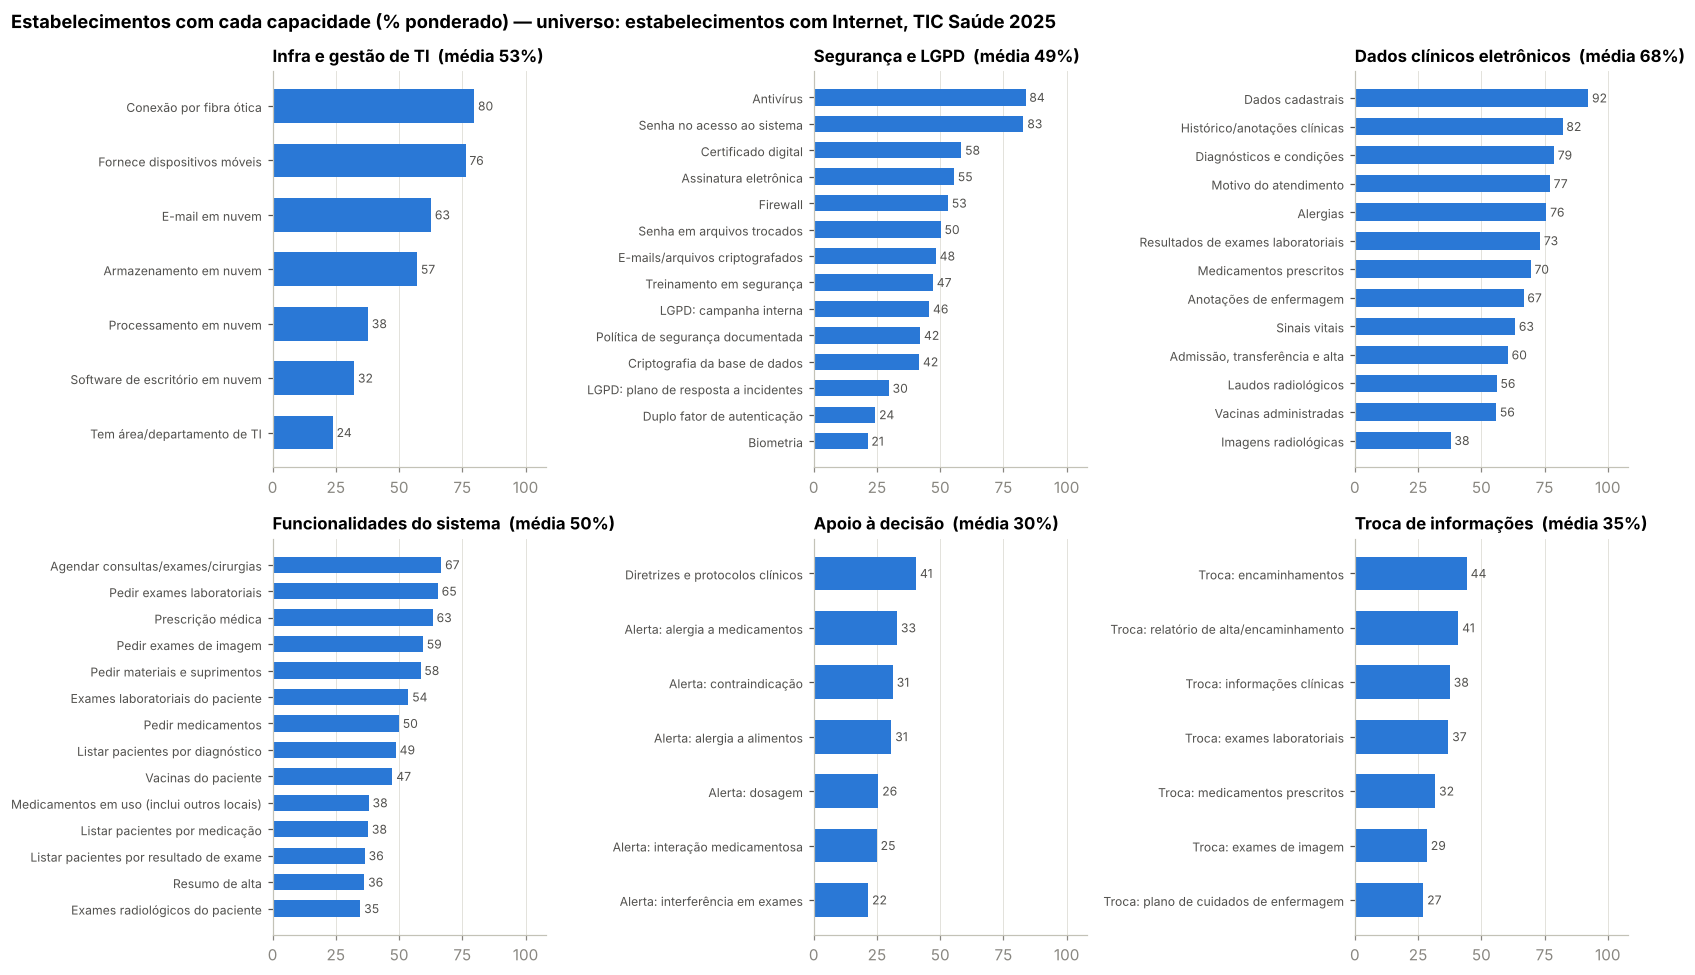

In [12]:
prev = pd.Series({i: prop(X[i].values, w) for i in ITENS})
fig, axes = plt.subplots(2, 3, figsize=(15, 9)); axes = axes.ravel()
for ax, (b, its) in zip(axes, BLOCOS.items()):
    p = prev[its].sort_values()
    ax.barh([NOME[i] for i in p.index], p.values, color='#2a78d6', height=.62)
    for y, v in enumerate(p.values): ax.text(v + 1.5, y, f'{v:.0f}', va='center', fontsize=8, color='#52514e')
    ax.set_xlim(0, 108); ax.set_title(f'{b}  (média {p.mean():.0f}%)'); ax.grid(axis='y', visible=False); ax.tick_params(axis='y', labelsize=8)
fig.suptitle('Estabelecimentos com cada capacidade (% ponderado) — universo: estabelecimentos com Internet, TIC Saúde 2025', x=.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(); salvar('01_prevalencia_itens'); plt.show()

### 5.3 As dimensões andam juntas?
Correlação ponderada entre os escores de bloco (proporção de "Sim" em cada bloco).

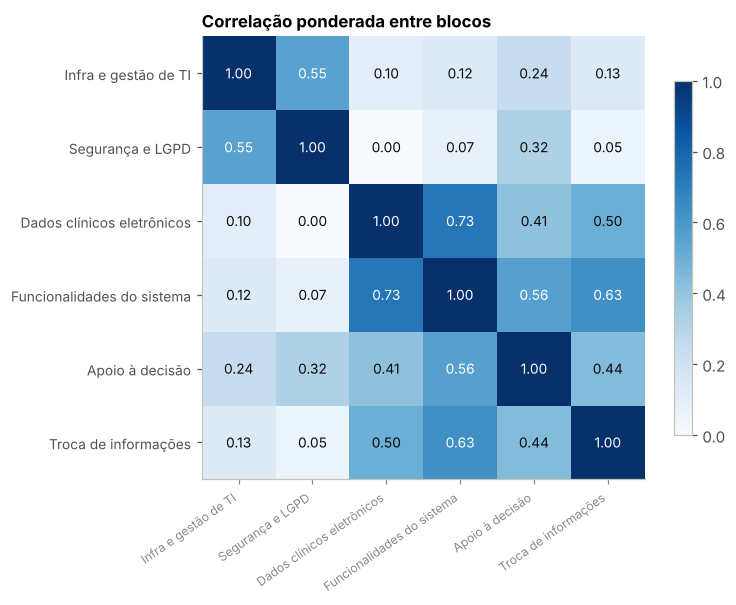

PCA nos 62 itens — variância explicada pelos 5 primeiros componentes: [0.242 0.099 0.042 0.037 0.03 ]

Carga média por bloco:
                              CP1    CP2
Infra e gestão de TI        0.055  0.143
Segurança e LGPD            0.054  0.193
Dados clínicos eletrônicos  0.138 -0.074
Funcionalidades do sistema  0.158 -0.035
Apoio à decisão             0.149  0.086
Troca de informações        0.152 -0.063


In [13]:
def corr_pond(A, w):
    m = np.average(A, axis=0, weights=w); Z = A - m
    cov = (Z * w[:, None]).T @ Z / w.sum(); d = np.sqrt(np.diag(cov))
    return cov / np.outer(d, d)
CB = pd.DataFrame(corr_pond(S.values, w), index=S.columns, columns=S.columns)
fig, ax = plt.subplots(figsize=(7.2, 5.6))
im = ax.imshow(CB.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(6)); ax.set_xticklabels(CB.columns, fontsize=8, rotation=35, ha='right'); ax.set_yticks(range(6)); ax.set_yticklabels(CB.index, fontsize=9)
for i in range(6):
    for j in range(6): ax.text(j, i, f'{CB.values[i, j]:.2f}', ha='center', va='center', color='white' if CB.values[i, j] > .55 else INK, fontsize=9)
ax.grid(False); ax.set_title('Correlação ponderada entre blocos'); plt.colorbar(im, shrink=.8)
plt.tight_layout(); salvar('02_correlacao_blocos'); plt.show()
pca = PCA(5, random_state=SEED).fit(X.values)
print('PCA nos 62 itens — variância explicada pelos 5 primeiros componentes:', pca.explained_variance_ratio_.round(3))
carg = pd.DataFrame(pca.components_[:2].T, index=ITENS, columns=['CP1', 'CP2'])
print('\nCarga média por bloco:'); print(carg.groupby(pd.Series(BLOCO_DE)).mean().loc[list(BLOCOS)].round(3).to_string())

**Leitura.**
- **Efeito teto no básico.** Computador (99%), Internet (99%) e sistema eletrônico de registro (92%) são quase universais. "Ter ou não ter" já não diferencia os estabelecimentos; o que varia é a **profundidade** (quais dados, quais funções, se há troca).
- **O gargalo é a troca.** 92% têm sistema eletrônico, mas só 27% dizem que ele troca dados diretamente com outros sistemas da rede; cada função de troca está presente em 27% a 44% dos estabelecimentos.
- **Duas dimensões, não uma.** Os blocos formam dois conjuntos: *infra + segurança* (correlação alta entre si) e *dados clínicos + funcionalidades + apoio à decisão + troca* (correlações altas entre si). Entre os dois conjuntos a correlação é baixa. A PCA mostra o mesmo: o 1º componente (24% da variância) carrega os blocos clínicos; o 2º (10%) opõe infra/segurança aos blocos clínicos. Um índice único de "maturidade" somaria coisas que não andam juntas.

## 6. Hipóteses H1 e H2 (antes do clustering)

- **H1.** Mais infraestrutura de TIC ↔ mais adoção de sistemas eletrônicos de saúde.
- **H2.** Gestão de TI mais estruturada ↔ mais troca eletrônica de informações.

Para cada uma: uma medida de associação ponderada e a mesma comparação **dentro** de cada esfera administrativa, para verificar se a relação se mantém quando se compara público com público e privado com privado.

In [14]:
u['n_troca'] = X[BLOCOS['Troca de informações']].sum(axis=1)
u['n_func']  = X[BLOCOS['Funcionalidades do sistema']].sum(axis=1)
def media_ic(base, col):
    v = base[col].values.astype(float)
    return est_ic(base, lambda d, ww: np.sum(v * ww) / np.sum(ww))
lin = []
for esf, fe in [('Todos', u.index >= 0), ('Público', u['COD_ESFADM_BASE'] == 1), ('Privado', u['COD_ESFADM_BASE'] == 2)]:
    for cond, nome_c in [('B3_4', 'Fibra ótica'), ('B8', 'Área de TI')]:
        for val_c, rot in [(1, 'Sim'), (0, 'Não')]:
            b = u[np.asarray(fe) & (u[cond] == val_c)]
            sis = prop_ic(b, b['C1_1'] == 1); fu = media_ic(b, 'n_func'); tr = media_ic(b, 'n_troca'); c8 = prop_ic(b, b['C8'] == 1)
            lin.append((esf, nome_c, rot, len(b), f'{sis[0]:.0f} ±{sis[1]:.0f}', f'{fu[0]:.1f} ±{fu[1]:.1f}', f'{tr[0]:.1f} ±{tr[1]:.1f}', f'{c8[0]:.0f} ±{c8[1]:.0f}'))
H = pd.DataFrame(lin, columns=['Esfera', 'Condição', 'Tem?', 'n', 'Sistema eletrônico (%)', 'Funcionalidades (0–14)', 'Funções de troca (0–7)', 'Troca sistema-a-sistema C8 (%)'])
H.to_csv('outputs/tables/hipoteses_h1_h2.csv', index=False)
resp = u['B8_4A'].map({1: 'Profissional do estabelecimento', 2: 'Prestador contratado pelo estabelecimento', 3: 'Prestador da Secretaria de Saúde', 99: 'Tem área de TI própria (pergunta não feita)'}).fillna('Outros / não sabe')
R4 = pd.DataFrame([(k, len(b), round(prop(np.ones(len(b)), b['PESO'].values) * b['PESO'].sum() / u['PESO'].sum(), 1), round(100 * np.average(b['COD_ESFADM_BASE'] == 1, weights=b['PESO'])), round(np.average(b['n_troca'], weights=b['PESO']), 1), round(100 * np.average(b['C8'] == 1, weights=b['PESO'])))
                   for k, b in u.groupby(resp)], columns=['Responsável pela TI (B8_4A)', 'n', '% dos estab.', '% público', 'Funções de troca (0–7)', 'C8 Sim (%)'])
print(H.to_string(index=False)); print(); print(R4.to_string(index=False))

 Esfera    Condição Tem?    n Sistema eletrônico (%) Funcionalidades (0–14) Funções de troca (0–7) Troca sistema-a-sistema C8 (%)
  Todos Fibra ótica  Sim 2634                  94 ±1               7.0 ±0.3               2.5 ±0.2                          27 ±3
  Todos Fibra ótica  Não  389                  85 ±6               6.9 ±1.0               2.4 ±0.3                          27 ±8
  Todos  Área de TI  Sim 1059                  96 ±2               7.5 ±0.4               2.5 ±0.3                          27 ±5
  Todos  Área de TI  Não 2153                  92 ±2               6.9 ±0.2               2.5 ±0.2                          27 ±4
Público Fibra ótica  Sim 1086                  92 ±2               9.1 ±0.4               3.7 ±0.3                          46 ±7
Público Fibra ótica  Não  241                  86 ±8               8.7 ±1.2               3.1 ±0.5                         40 ±12
Público  Área de TI  Sim  315                  91 ±4               9.2 ±0.7               

**H1 — infraestrutura ↔ adoção de sistemas: apoio fraco, limitado pelo efeito teto.**
Estabelecimentos com fibra têm um pouco mais de sistema eletrônico (94% contra 85%), mas a adoção é alta nos dois grupos e o número de funcionalidades é praticamente igual (7,0 contra 6,9). A profundidade do sistema só acompanha a estrutura de TI **no setor privado** (6,9 funcionalidades com área de TI contra 4,5 sem); no setor público não há diferença (9,2 contra 9,0).

**H2 — gestão de TI ↔ troca de informações: não se sustenta no agregado; vale apenas no setor privado.**
No total, ter ou não área de TI não muda a troca (2,5 funções nos dois casos; 27% de troca sistema-a-sistema nos dois). Separando por esfera, o quadro muda: no privado, área de TI acompanha mais troca (2,2 contra 1,4 funções; 20% contra 11% em C8); no público a diferença é pequena e as margens se sobrepõem. O agregado esconde a relação porque os estabelecimentos públicos têm **menos** estrutura local de TI e **mais** troca.

**Pista para interpretar.** Onde a TI é provida pela Secretaria de Saúde (100% públicos, cerca de um terço dos estabelecimentos), a troca é a mais alta (3,6 funções; 43% em C8). Uma explicação plausível é que a capacidade de troca venha com o sistema fornecido pela rede pública, e não da estrutura de TI de cada unidade. Os dados mostram a associação; **não** identificam qual sistema é usado nem provam o mecanismo.

## 7. Clustering

### 7.1 Representação e algoritmo — justificativa

- **Todos os 62 atributos são binários e estão na mesma escala.** Não há variável nominal com várias categorias nem variável contínua, então não é preciso distância de Gower nem k-prototypes.
- **Para vetores 0/1, a distância euclidiana ao quadrado é igual à distância de Hamming** (o número de itens em que dois estabelecimentos discordam). O k-means, portanto, minimiza discordâncias em relação a um centróide cujo valor em cada item é a **proporção de "Sim" no grupo** — exatamente a leitura que interessa. Não há normalização a fazer.
- **Alternativa natural para dados categóricos:** k-modes (centróide = moda, distância = discordâncias simples). É comparado em todas as etapas.
- **Peso dos blocos.** Blocos com mais itens pesam mais na distância. Isso é avaliado na seção 8 com uma representação alternativa em que cada bloco pesa igual.
- **Pesos amostrais.** O agrupamento principal é feito **sem** ponderação: descreve a estrutura da amostra. A prevalência dos perfis na população é estimada depois, com pesos. A seção 8 refaz o k-means ponderado para medir a diferença.

### 7.2 Quantos grupos?
Para k de 2 a 7: silhouette (distância de Hamming), Davies–Bouldin e **estabilidade** — o modelo é reajustado em reamostras bootstrap, reaplicado a todos os estabelecimentos e comparado com a solução original pelo índice de Rand ajustado (ARI; 1 = partições idênticas).

In [15]:
Xv = X.values
def rot_kmeans(A, k, seed, aplicar=None, n_init=10):
    m = KMeans(k, n_init=n_init, random_state=seed).fit(A)
    return m.labels_ if aplicar is None else m.predict(aplicar)
def rot_kmodes(A, k, seed, aplicar=None, n_init=5):
    m = KModes(k, init='Huang', n_init=n_init, random_state=seed).fit(A)
    return m.labels_ if aplicar is None else m.predict(aplicar)
def estabilidade(rotular, k, B, seed=SEED):
    rng = np.random.default_rng(seed); base = rotular(Xv, k, seed); ari = []
    for b in range(B):
        idx = rng.choice(len(Xv), len(Xv), replace=True)
        ari.append(adjusted_rand_score(base, rotular(Xv[idx], k, seed + b + 1, aplicar=Xv)))
    estabilidade.ultimo = np.array(ari)
    return np.mean(ari), np.min(ari)
lin = []
for nome, rotular, B in [('k-means', rot_kmeans, 30), ('k-modes', rot_kmodes, 10)]:
    for k in range(2, 8):
        lb = rotular(Xv, k, SEED); em, emin = estabilidade(rotular, k, B)
        lin.append((nome, k, silhouette_score(Xv, lb, metric='hamming'), davies_bouldin_score(Xv, lb), em, emin, np.bincount(lb).min()))
SEL = pd.DataFrame(lin, columns=['Algoritmo', 'k', 'Silhouette (Hamming)', 'Davies–Bouldin', 'ARI médio (bootstrap)', 'ARI mínimo', 'Menor grupo (n)'])
SEL.to_csv('outputs/tables/selecao_k.csv', index=False); SEL.round(3)

,Algoritmo,k,Silhouette (Hamming),Davies–Bouldin,ARI médio (bootstrap),ARI mínimo,Menor grupo (n)
0,k-means,2,0.285,2.138,0.968,0.888,1458
1,k-means,3,0.216,2.482,0.944,0.871,964
2,k-means,4,0.186,2.665,0.879,0.482,696
3,k-means,5,0.157,2.831,0.824,0.536,533
4,k-means,6,0.135,2.832,0.864,0.676,488
5,k-means,7,0.123,2.981,0.775,0.537,425
6,k-modes,2,0.275,2.176,0.975,0.909,1563
7,k-modes,3,0.211,2.494,0.903,0.807,998
8,k-modes,4,0.185,2.729,0.794,0.738,644
9,k-modes,5,0.156,2.970,0.646,0.506,475


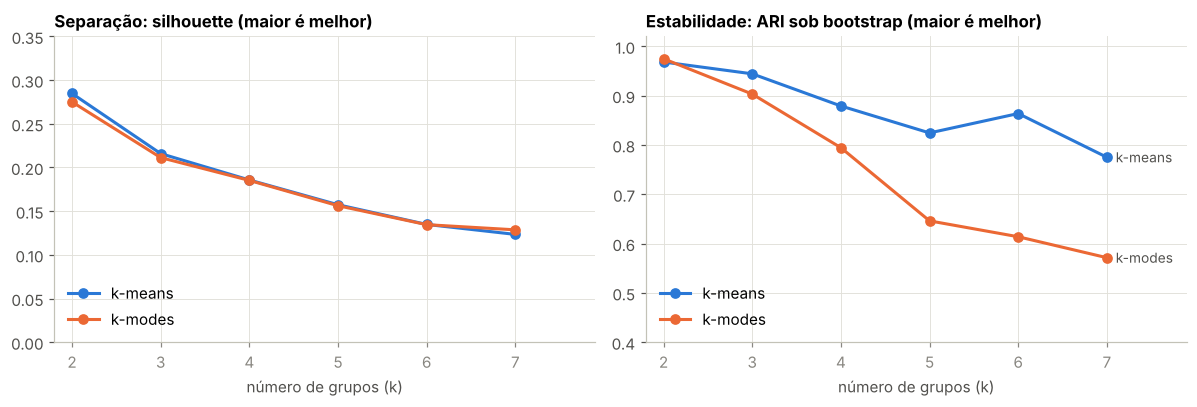

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for nome, cor in [('k-means', '#2a78d6'), ('k-modes', '#eb6834')]:
    t = SEL[SEL['Algoritmo'] == nome]
    ax[0].plot(t['k'], t['Silhouette (Hamming)'], marker='o', lw=2, color=cor, label=nome)
    ax[1].plot(t['k'], t['ARI médio (bootstrap)'], marker='o', lw=2, color=cor, label=nome)
    ax[1].text(7.1, t['ARI médio (bootstrap)'].iloc[-1], nome, color='#52514e', va='center', fontsize=9)
ax[0].set_title('Separação: silhouette (maior é melhor)'); ax[1].set_title('Estabilidade: ARI sob bootstrap (maior é melhor)')
for a in ax: a.set_xlabel('número de grupos (k)'); a.set_xlim(1.8, 7.9); a.legend(loc='lower left')
ax[0].set_ylim(0, .35); ax[1].set_ylim(.4, 1.02)
plt.tight_layout(); salvar('03_selecao_k'); plt.show()

**Leitura e decisão.**
- O silhouette é **baixo em qualquer k** (máximo de 0,29 em k = 2) e cai continuamente. Não há um número "natural" de grupos bem separados: os estabelecimentos formam um **contínuo**, e o agrupamento é uma segmentação útil desse contínuo, não a descoberta de classes discretas. Isso é um resultado, não um defeito a esconder.
- k = 2 separa apenas "mais digitalizados" de "menos digitalizados" e ignora a segunda dimensão vista na seção 5.3.
- **k = 4 com k-means** é o maior k que ainda mantém estabilidade alta na média (ARI ≈ 0,88) e é o primeiro a separar as duas dimensões. A partir de k = 5 a estabilidade cai e os grupos passam a subdividir o mesmo eixo.
- O ARI mínimo de k = 4 mostra que, em uma minoria das reamostras, o algoritmo converge para outra partição. A seção 8 quantifica isso.
- O **k-means** é mais estável que o k-modes em todos os k ≥ 3 e é adotado como principal.

### 7.3 Solução escolhida: k-means, k = 4

In [17]:
K = 4
km = KMeans(K, n_init=50, random_state=SEED).fit(Xv)
bruto = km.labels_
cb = S.groupby(bruto).mean()                                  # escores de bloco por grupo
eixo_ti  = cb[['Infra e gestão de TI', 'Segurança e LGPD']].mean(axis=1)
eixo_cli = cb[['Dados clínicos eletrônicos', 'Funcionalidades do sistema', 'Apoio à decisão', 'Troca de informações']].mean(axis=1)
# Ordenação determinística dos grupos (os nomes foram dados depois de ler os centróides)
A_ = (eixo_ti + eixo_cli).idxmax(); D_ = (eixo_ti + eixo_cli).idxmin()
meio = [c for c in cb.index if c not in (A_, D_)]
B_ = max(meio, key=lambda c: eixo_cli[c] - eixo_ti[c]); C_ = [c for c in meio if c != B_][0]
ordem = {A_: 0, B_: 1, C_: 2, D_: 3}
perfil = np.array([ordem[c] for c in bruto]); u['perfil'] = perfil
PERFIS = ['A · Integrado avançado', 'B · Conectado, TI enxuta', 'C · TI estruturada, pouca troca', 'D · Digitalização básica']
CURTO  = ['A', 'B', 'C', 'D']
print('Silhouette (Hamming):', round(silhouette_score(Xv, perfil, metric='hamming'), 3))
resumo = (100 * S.groupby(perfil).mean()).round(0).astype(int); resumo.index = PERFIS
resumo.insert(0, 'n (amostra)', np.bincount(perfil)); resumo

Silhouette (Hamming): 0.186


,n (amostra),Infra e gestão de TI,Segurança e LGPD,Dados clínicos eletrônicos,Funcionalidades do sistema,Apoio à decisão,Troca de informações
A · Integrado avançado,855,73,72,92,84,77,71
"B · Conectado, TI enxuta",936,42,32,87,64,23,50
"C · TI estruturada, pouca troca",747,67,68,64,36,22,15
D · Digitalização básica,696,41,38,26,14,5,10


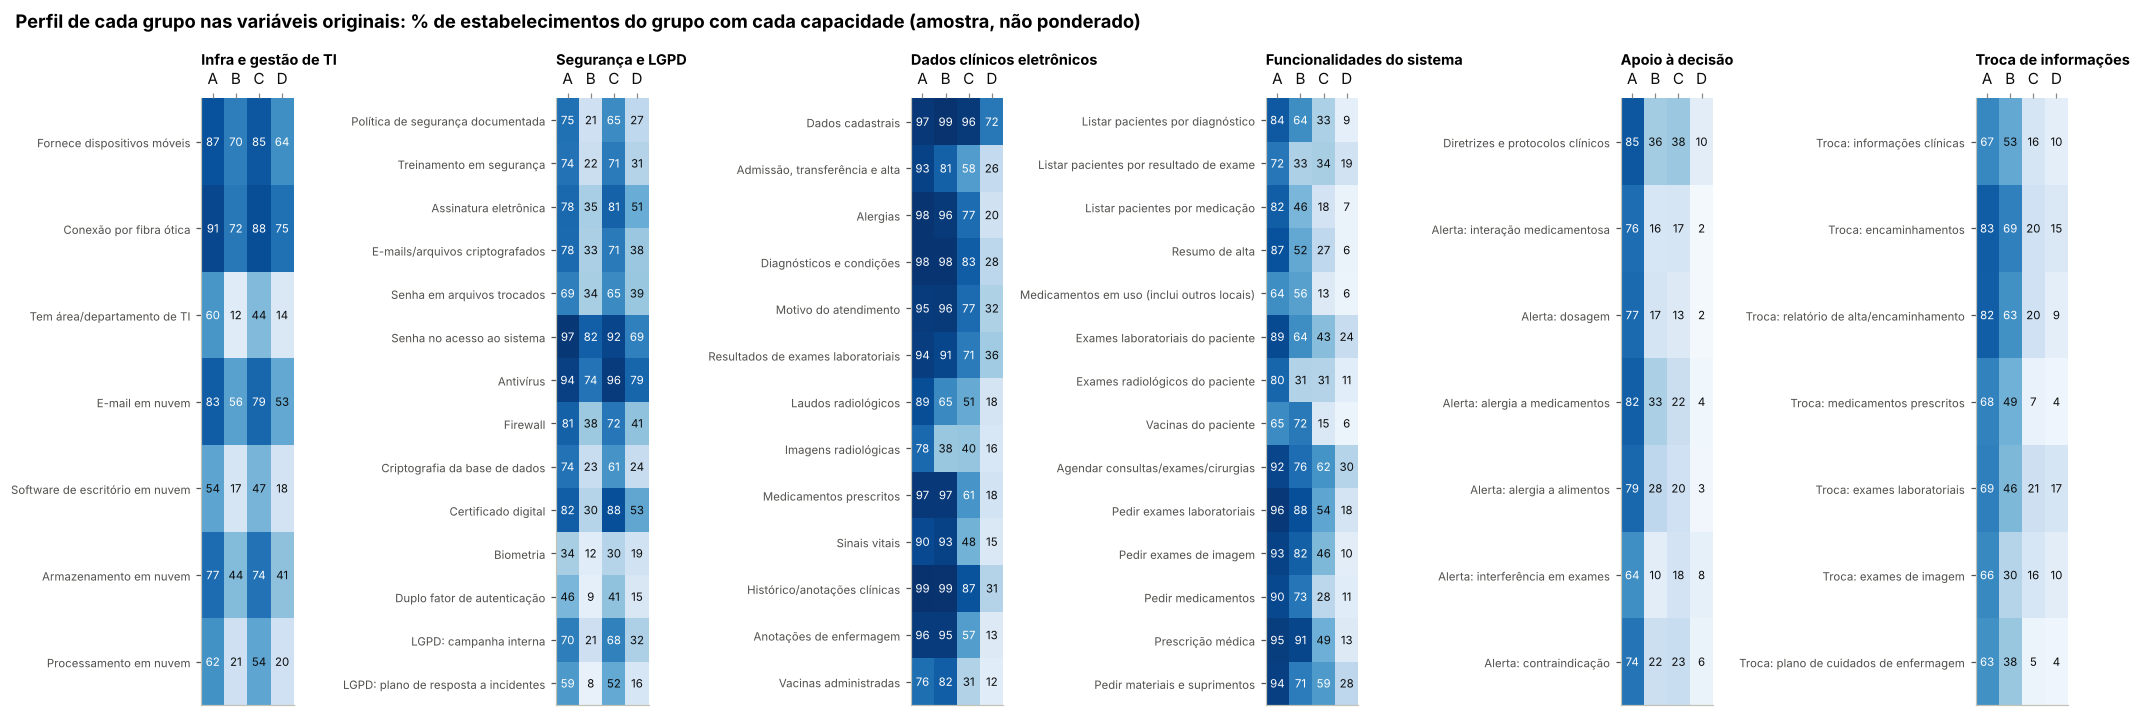

In [18]:
cent = 100 * X.groupby(perfil).mean().T                       # % de "Sim" por item e perfil
fig, axes = plt.subplots(1, 6, figsize=(19, 6.6))
for ax, (b, its) in zip(axes, BLOCOS.items()):
    M = cent.loc[its].values
    ax.imshow(M, cmap='Blues', vmin=0, vmax=100, aspect='auto')
    ax.set_yticks(range(len(its))); ax.set_yticklabels([NOME[i][:42] for i in its], fontsize=7.5)
    ax.set_xticks(range(4)); ax.set_xticklabels(CURTO, fontsize=10, color=INK); ax.xaxis.tick_top(); ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(4): ax.text(j, i, f'{M[i, j]:.0f}', ha='center', va='center', fontsize=7.5, color='white' if M[i, j] > 55 else INK)
    ax.set_title(b, fontsize=9.5, pad=22)
fig.suptitle('Perfil de cada grupo nas variáveis originais: % de estabelecimentos do grupo com cada capacidade (amostra, não ponderado)', x=.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(); salvar('04_heatmap_itens'); plt.show()

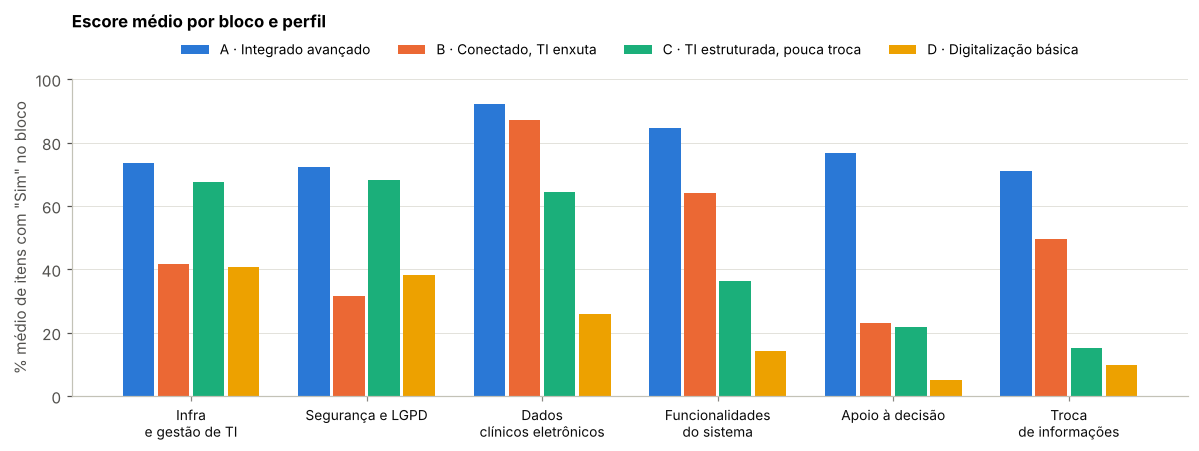

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.2))
bl = list(BLOCOS); xpos = np.arange(len(bl)); larg = .2
for j in range(4):
    v = 100 * S.groupby(perfil).mean().loc[j, bl].values
    ax.bar(xpos + (j - 1.5) * larg, v, larg - .02, color=COR[j], label=PERFIS[j])
ax.set_xticks(xpos); ax.set_xticklabels([b.replace(' ', '\n', 1) if len(b) > 16 else b for b in bl], fontsize=9, color=INK)
ax.set_ylabel('% médio de itens com "Sim" no bloco'); ax.set_ylim(0, 100); ax.grid(axis='x', visible=False)
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, 1.16), fontsize=9); ax.set_title('Escore médio por bloco e perfil', pad=34)
plt.tight_layout(); salvar('05_blocos_por_perfil'); plt.show()

In [20]:
# Quais dimensões e itens mais separam os perfis? (eta²: parcela da variância explicada pelos grupos)
def eta2(v, g):
    v = np.asarray(v, float); m = v.mean()
    return sum((g == k).sum() * (v[g == k].mean() - m) ** 2 for k in np.unique(g)) / ((v - m) ** 2).sum()
e_bloco = pd.Series({b: eta2(S[b], perfil) for b in BLOCOS}).sort_values(ascending=False)
e_item  = pd.Series({i: eta2(X[i], perfil) for i in ITENS}).sort_values(ascending=False)
print('eta² por bloco:'); print(e_bloco.round(2).to_string())
top = pd.DataFrame({'Item': [NOME[i] for i in e_item.index[:12]], 'Bloco': [BLOCO_DE[i] for i in e_item.index[:12]], 'eta²': e_item.values[:12].round(2)})
top = pd.concat([top, cent.loc[e_item.index[:12]].round(0).astype(int).reset_index(drop=True).set_axis(CURTO, axis=1)], axis=1); top

eta² por bloco:
Funcionalidades do sistema    0.72
Dados clínicos eletrônicos    0.71
Apoio à decisão               0.54
Segurança e LGPD              0.48
Troca de informações          0.46
Infra e gestão de TI          0.29


,Item,Bloco,eta²,A,B,C,D
0,Anotações de enfermagem,Dados clínicos eletrônicos,0.51,96,95,57,13
1,Alergias,Dados clínicos eletrônicos,0.50,98,96,77,20
2,Medicamentos prescritos,Dados clínicos eletrônicos,0.48,97,97,61,18
3,Histórico/anotações clínicas,Dados clínicos eletrônicos,0.48,99,99,87,31
4,Prescrição médica,Funcionalidades do sistema,0.48,95,91,49,13
5,Diagnósticos e condições,Dados clínicos eletrônicos,0.46,98,98,83,28
6,Sinais vitais,Dados clínicos eletrônicos,0.44,90,93,48,15
7,Alerta: dosagem,Apoio à decisão,0.43,77,17,13,2
8,Pedir exames de imagem,Funcionalidades do sistema,0.42,93,82,46,10
9,Pedir exames laboratoriais,Funcionalidades do sistema,0.42,96,88,54,18


**Os quatro perfis** (nomes atribuídos depois de ler os centróides nas variáveis originais):

| Perfil | O que o caracteriza |
|---|---|
| **A · Integrado avançado** | Alto em tudo: registro clínico completo, apoio à decisão (alertas em ~75%), troca em 63–83% dos itens, segurança estruturada, 60% com área de TI. |
| **B · Conectado, TI enxuta** | Registro clínico tão completo quanto o de A e troca intermediária (encaminhamentos 69%), mas pouca estrutura própria: 12% com área de TI, 21% com política de segurança, 8% com plano de resposta a incidentes. |
| **C · TI estruturada, pouca troca** | Infra e segurança no nível de A (nuvem, certificado digital, política de segurança), sistema clínico parcial e **troca rara** (5–21% dos itens). |
| **D · Digitalização básica** | Baixo em tudo, exceto o essencial: dados cadastrais (72%), antivírus, senha. |

**Qual dimensão mais separa os grupos?** O conteúdo e as funções do sistema clínico (η² ≈ 0,7), seguidos de apoio à decisão, segurança e troca (≈ 0,5). Infraestrutura é a que menos distingue (0,29). Os alertas de apoio à decisão são quase exclusivos do perfil A.

B e C são o achado central: têm níveis parecidos de "maturidade" se tudo for somado, mas em **dimensões opostas**.

## 8. Robustez

Cinco perturbações razoáveis, cada uma comparada à solução principal pelo ARI:
1. **k-means ponderado** pelos pesos amostrais;
2. **k-modes** (outro algoritmo, mesma representação);
3. **excluir** os estabelecimentos em que o gestor não soube responder mais de 20% dos itens;
4. **k-means nos 6 escores de bloco** (cada bloco com o mesmo peso, em vez de cada item);
5. **agrupamento hierárquico de Ward** nos itens.

Além do ARI, mede-se a **retenção**: que parcela dos membros de cada perfil principal continua junta no grupo correspondente da solução alternativa.

In [21]:
mant = (ns_share <= .2).values
alt = {'k-means ponderado (pesos amostrais)': KMeans(K, n_init=50, random_state=SEED).fit(Xv, sample_weight=w).labels_,
       'k-modes': KModes(K, init='Huang', n_init=20, random_state=SEED).fit_predict(Xv),
       'k-means nos escores de bloco': KMeans(K, n_init=50, random_state=SEED).fit(S.values).labels_,
       'Hierárquico (Ward)': AgglomerativeClustering(K, linkage='ward').fit_predict(Xv)}
lin = []
def comparar(nome, ref, lb):
    ct = pd.crosstab(ref, lb).values
    r, c = linear_sum_assignment(-ct)                           # melhor pareamento entre grupos
    ret = ct[r, c] / ct.sum(axis=1)
    lin.append((nome, len(ref), round(adjusted_rand_score(ref, lb), 2), *[round(100 * x) for x in ret]))
for nome, lb in alt.items(): comparar(nome, perfil, lb)
comparar('Sem gestores com >20% de "não sabe"', perfil[mant], KMeans(K, n_init=50, random_state=SEED).fit(Xv[mant]).labels_)
em, emin = estabilidade(lambda A, k, s, aplicar=None: rot_kmeans(A, k, s, aplicar), K, 50)
ROB = pd.DataFrame(lin, columns=['Variação', 'n', 'ARI vs. principal'] + [f'Retenção {c} (%)' for c in CURTO])
ROB.to_csv('outputs/tables/robustez.csv', index=False)
ar = estabilidade.ultimo
print(f'Bootstrap (50 reamostras): ARI médio {em:.2f} | mediana {np.median(ar):.2f} | mínimo {emin:.2f} | reamostras com ARI >= 0,80: {100*np.mean(ar >= .8):.0f}%')
ROB

Bootstrap (50 reamostras): ARI médio 0.89 | mediana 0.90 | mínimo 0.48 | reamostras com ARI >= 0,80: 96%


,Variação,n,ARI vs. principal,Retenção A (%),Retenção B (%),Retenção C (%),Retenção D (%)
0,k-means ponderado (pesos amostrais),3234,0.82,100,87,94,92
1,k-modes,3234,0.69,89,81,81,98
2,k-means nos escores de bloco,3234,0.48,80,54,67,95
3,Hierárquico (Ward),3234,0.34,70,63,51,72
4,"Sem gestores com >20% de ""não sabe""",3048,0.95,95,99,99,100


In [22]:
# Os mesmos arquétipos aparecem nas alternativas? Escore de bloco (%) por grupo, em cada método
for nome in ['k-means nos escores de bloco', 'Hierárquico (Ward)']:
    t = (100 * S.groupby(alt[nome]).mean()).round(0).astype(int); t.insert(0, 'n', np.bincount(alt[nome]))
    print(nome); print(t.sort_values('Troca de informações', ascending=False).to_string(), '\n')

k-means nos escores de bloco
     n  Infra e gestão de TI  Segurança e LGPD  Dados clínicos eletrônicos  Funcionalidades do sistema  Apoio à decisão  Troca de informações
3  669                    49                40                          89                          71               25                    77
1  781                    74                72                          89                          81               87                    66
2  953                    54                49                          79                          48               18                    15
0  831                    47                46                          27                          16                7                    10 

Hierárquico (Ward)
     n  Infra e gestão de TI  Segurança e LGPD  Dados clínicos eletrônicos  Funcionalidades do sistema  Apoio à decisão  Troca de informações
2  674                    73                73                          91                        

**Leitura.**
- **Robusto a pesos, a "não sabe" e a reamostragem.** k-means ponderado: ARI 0,82. Sem os gestores com muitas respostas "não sabe": 0,95. Bootstrap: ARI médio 0,89, com 96% das reamostras acima de 0,80.
- **Sensível à representação.** Com cada bloco pesando igual (ARI 0,48) ou com Ward (0,34), a partição muda bastante.
- **O que se mantém em todos os métodos:** um grupo avançado, um grupo básico e a separação entre quem troca informações e quem não troca.
- **O que depende do método:** a fronteira entre os perfis intermediários. Na representação por itens, o bloco de segurança (14 itens) pesa mais e separa B de C pelo eixo de TI; quando os blocos pesam igual, os grupos do meio se organizam mais pelo eixo da troca.

**Conclusão de robustez.** Os extremos (A e D) e o contraste "troca × não troca" são estruturais. A divisão exata entre B e C deve ser lida como uma descrição útil das duas dimensões encontradas na seção 5.3, não como uma fronteira nítida. Grupos pequenos não são um problema: o menor tem 696 estabelecimentos.

## 9. Caracterização dos perfis e validação externa
A partir daqui tudo é **ponderado**: as porcentagens estimam a população de estabelecimentos com Internet. As margens (±) vêm das réplicas e devem ser lidas como aproximadas (seção 2.2).
### 9.1 Tamanho de cada perfil

In [23]:
tam = []
for j in range(4):
    p, m = prop_ic(u, perfil == j)
    tam.append((PERFIS[j], int((perfil == j).sum()), round(p, 1), round(m, 1), int(round(u['PESO'].sum() * p / 100, -2))))
TAM = pd.DataFrame(tam, columns=['Perfil', 'n (amostra)', '% dos estabelecimentos', '± (95%)', 'Estabelecimentos (estimativa)'])
TAM.to_csv('outputs/tables/tamanho_perfis.csv', index=False); TAM

,Perfil,n (amostra),% dos estabelecimentos,± (95%),Estabelecimentos (estimativa)
0,A · Integrado avançado,855,19.7,2.5,25300
1,"B · Conectado, TI enxuta",936,32.4,2.8,41500
2,"C · TI estruturada, pouca troca",747,25.7,2.1,32800
3,D · Digitalização básica,696,22.2,2.5,28400


### 9.2 Quem está em cada perfil

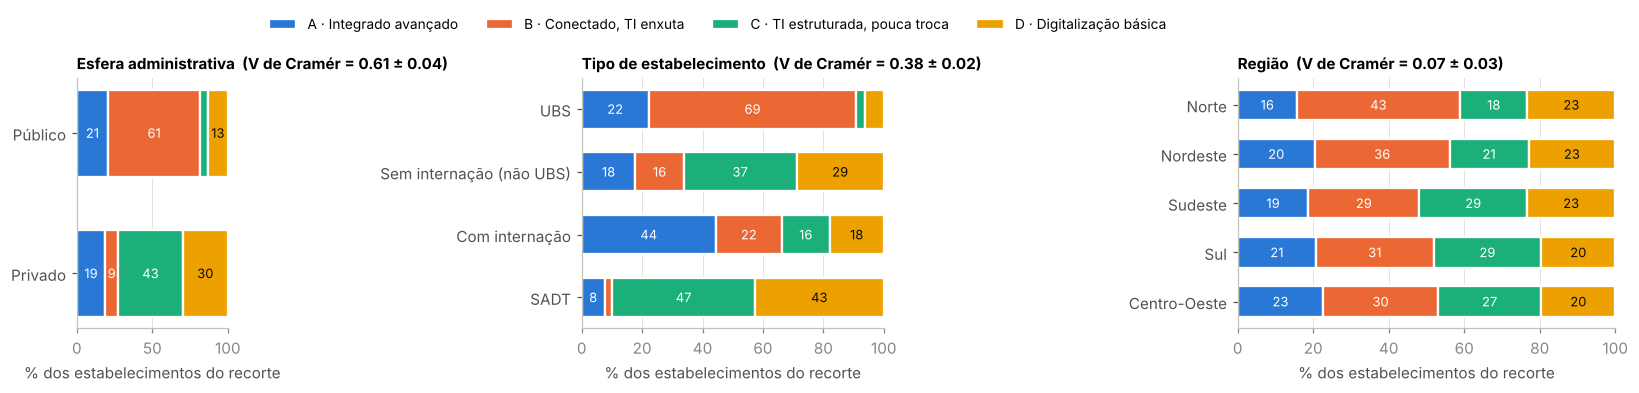

A   B   C   D
esfera Público                   21  61   5  13
       Privado                   19   9  43  30
tipo4  UBS                       22  69   3   6
       Sem internação (não UBS)  18  16  37  29
       Com internação            44  22  16  18
       SADT                       8   3  47  43
regiao Norte                     16  43  18  23
       Nordeste                  20  36  21  23
       Sudeste                   19  29  29  23
       Sul                       21  31  29  20
       Centro-Oeste              23  30  27  20

In [24]:
u['tipo4'] = np.select([u['UBS'] == 1, u['TIPO_CETIC_TAB'] == 1, u['TIPO_CETIC_TAB'] == 3], ['UBS', 'Com internação', 'SADT'], 'Sem internação (não UBS)')
u['esfera'] = u['COD_ESFADM_BASE'].map(ROT['COD_ESFADM_BASE']); u['regiao'] = u['COD_REGIAO'].map(ROT['COD_REGIAO'])
CTX = {'esfera': ['Público', 'Privado'], 'tipo4': ['UBS', 'Sem internação (não UBS)', 'Com internação', 'SADT'],
       'regiao': ['Norte', 'Nordeste', 'Sudeste', 'Sul', 'Centro-Oeste']}
def dist_perfis(col, cats):
    return pd.DataFrame({c: [prop((perfil == j)[(u[col] == c).values], w[(u[col] == c).values]) for j in range(4)] for c in cats}, index=CURTO).T
def cramer_v(col, ww):
    t = pd.crosstab(u[col], perfil, values=ww, aggfunc='sum').fillna(0).values; t = t / t.sum()
    e = np.outer(t.sum(1), t.sum(0)); return np.sqrt(((t - e) ** 2 / e).sum() / (min(t.shape) - 1))
DIST = {c: dist_perfis(c, cats) for c, cats in CTX.items()}
V = {}
for c in CTX:
    v0 = cramer_v(c, w); vr = np.array([cramer_v(c, w * u[REPS[j]].values) for j in range(len(REPS))])
    V[c] = (v0, 1.96 * np.sqrt(np.mean((vr - v0) ** 2)))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), gridspec_kw={'width_ratios': [2, 4, 5]})
tit = {'esfera': 'Esfera administrativa', 'tipo4': 'Tipo de estabelecimento', 'regiao': 'Região'}
for ax, c in zip(axes, CTX):
    D = DIST[c]; esq = np.zeros(len(D))
    for j in range(4):
        ax.barh(D.index, D[CURTO[j]], left=esq, color=COR[j], height=.62, edgecolor='white', linewidth=1.5, label=PERFIS[j])
        for y, (v, e0) in enumerate(zip(D[CURTO[j]], esq)):
            if v >= 7: ax.text(e0 + v / 2, y, f'{v:.0f}', ha='center', va='center', fontsize=8.5, color=INK if j == 3 else 'white')
        esq += D[CURTO[j]].values
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis='y', visible=False); ax.set_xlabel('% dos estabelecimentos do recorte')
    ax.set_title(f'{tit[c]}  (V de Cramér = {V[c][0]:.2f} ± {V[c][1]:.2f})', fontsize=10)
axes[1].legend(ncol=4, loc='upper center', bbox_to_anchor=(.45, 1.3), fontsize=9)
plt.tight_layout(); salvar('06_perfis_por_contexto'); plt.show()
for c in CTX: DIST[c].round(1).to_csv(f'outputs/tables/perfis_por_{c}.csv')
pd.concat(DIST).round(0).astype(int)

In [25]:
# Composição de cada perfil (leitura inversa: dentro do perfil, quem são?)
comp = pd.DataFrame({PERFIS[j]: {'% público': prop((u['esfera'] == 'Público').values[perfil == j], w[perfil == j]),
    '% UBS': prop((u['tipo4'] == 'UBS').values[perfil == j], w[perfil == j]),
    '% sem internação (não UBS)': prop((u['tipo4'] == 'Sem internação (não UBS)').values[perfil == j], w[perfil == j]),
    '% com internação': prop((u['tipo4'] == 'Com internação').values[perfil == j], w[perfil == j]),
    '% SADT': prop((u['tipo4'] == 'SADT').values[perfil == j], w[perfil == j])} for j in range(4)}).T.round(0).astype(int)
comp.to_csv('outputs/tables/composicao_perfis.csv'); comp

,% público,% UBS,% sem internação (não UBS),% com internação,% SADT
A · Integrado avançado,48,37,44,14,5
"B · Conectado, TI enxuta",86,71,24,4,1
"C · TI estruturada, pouca troca",9,4,71,4,22
D · Digitalização básica,27,9,63,5,23


### 9.3 Validação externa: variáveis que não entraram no agrupamento

In [26]:
EXT = [('Sistema troca dados com outros sistemas da rede (C8)', u['C8'] == 1),
       ('Integrado à RNDS — Sim (C9)', u['C9'] == 1),
       ('Integrado à RNDS — gestor não sabe (C9)', u['C9'] == 97),
       ('Prontuário acessível fora do estabelecimento, pela Internet (C4A_3)', u['C4A_3'] == 1),
       ('Prontuário apenas em formato eletrônico (C1)', u['C1'] == 1),
       ('Oferece teleconsulta (D2_10)', u['D2_10'] == 1),
       ('Usou inteligência artificial (H3_2A)', u['H3_2A'] == 1),
       ('Usou blockchain — Sim (H3_1A)', u['H3_1A'] == 1),
       ('Usou blockchain — gestor não sabe (H3_1A)', u['H3_1A'] == 97)]
lin = []; EXTN = {}
for nome, ind in EXT:
    ind = np.asarray(ind); linha = [nome]; tot = prop_ic(u, ind)
    for j in range(4):
        b = u[perfil == j]; p, m = prop_ic(b, ind[perfil == j]); linha.append(f'{p:.0f} ±{m:.0f}'); EXTN[(nome, j)] = (p, m)
    EXTN[(nome, 'T')] = tot; lin.append(linha + [f'{tot[0]:.0f} ±{tot[1]:.0f}'])
EXTT = pd.DataFrame(lin, columns=['Indicador (% ponderado ± margem 95%)'] + CURTO + ['Total'])
EXTT.to_csv('outputs/tables/validacao_externa.csv', index=False); EXTT

,Indicador (% ponderado ± margem 95%),A,B,C,D,Total
0,Sistema troca dados com outros sistemas da rede (C8),50 ±8,38 ±6,13 ±4,7 ±3,27 ±3
1,Integrado à RNDS — Sim (C9),63 ±6,59 ±6,29 ±5,23 ±6,44 ±3
2,Integrado à RNDS — gestor não sabe (C9),16 ±4,26 ±6,25 ±5,21 ±4,23 ±3
3,"Prontuário acessível fora do estabelecimento, pela Internet (C4A_3)",54 ±6,64 ±6,44 ±6,26 ±6,48 ±3
4,Prontuário apenas em formato eletrônico (C1),39 ±7,40 ±6,42 ±5,23 ±5,37 ±3
5,Oferece teleconsulta (D2_10),44 ±7,33 ±7,25 ±5,11 ±4,28 ±3
6,Usou inteligência artificial (H3_2A),26 ±5,9 ±4,31 ±5,11 ±3,18 ±2
7,Usou blockchain — Sim (H3_1A),5 ±2,0 ±1,2 ±2,1 ±1,2 ±1
8,Usou blockchain — gestor não sabe (H3_1A),31 ±7,29 ±6,21 ±4,24 ±6,26 ±3


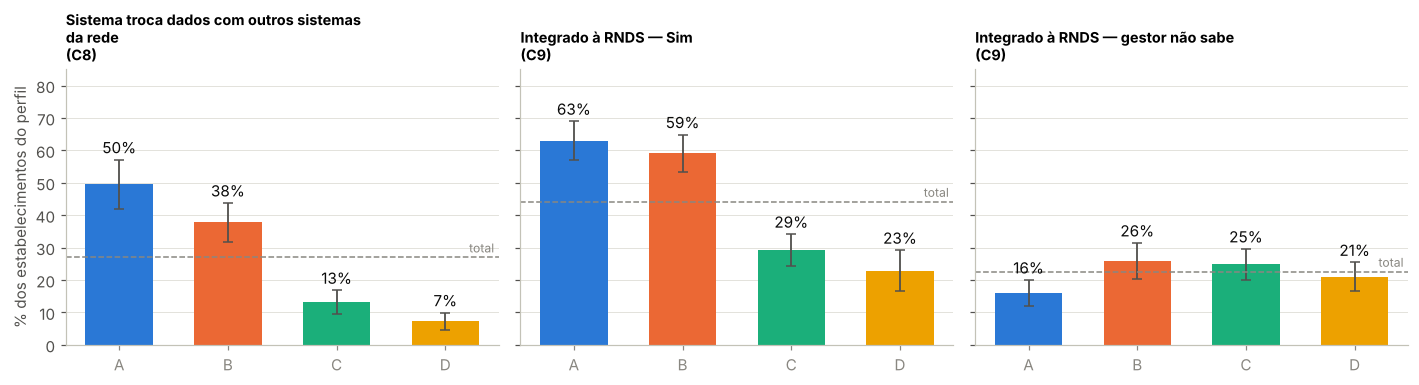

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (nome, _) in zip(axes, EXT[:3]):
    p = [EXTN[(nome, j)][0] for j in range(4)]; m = [EXTN[(nome, j)][1] for j in range(4)]
    ax.bar(CURTO, p, color=COR, width=.62, yerr=m, error_kw={'ecolor': '#52514e', 'elinewidth': 1.2, 'capsize': 3})
    for x, (v, e) in enumerate(zip(p, m)): ax.text(x, v + e + 2, f'{v:.0f}%', ha='center', fontsize=10, color=INK)
    ax.axhline(EXTN[(nome, 'T')][0], color=MUTED, lw=1, ls='--'); ax.text(3.45, EXTN[(nome, 'T')][0] + 1.5, 'total', ha='right', fontsize=8, color=MUTED)
    ax.set_title(nome.replace(' (C', '\n(C').replace(' da rede', '\nda rede'), fontsize=9.5); ax.set_ylim(0, 85); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('% dos estabelecimentos do perfil')
plt.tight_layout(); salvar('07_validacao_externa'); plt.show()

In [28]:
# O perfil ainda distingue a troca sistema-a-sistema quando se olha dentro de cada esfera?
lin = []
for esf in ['Público', 'Privado']:
    for nome_i, ind in [('C8 Sim', u['C8'] == 1), ('RNDS Sim', u['C9'] == 1)]:
        linha = [esf, nome_i]
        for j in range(4):
            f = (perfil == j) & (u['esfera'] == esf).values; b = u[f]; p, m = prop_ic(b, np.asarray(ind)[f]); linha.append(f'{p:.0f} ±{m:.0f} (n={f.sum()})')
        lin.append(linha)
ESF = pd.DataFrame(lin, columns=['Esfera', 'Indicador (%)'] + CURTO); ESF.to_csv('outputs/tables/validacao_por_esfera.csv', index=False); ESF

,Esfera,Indicador (%),A,B,C,D
0,Público,C8 Sim,72 ±13 (n=361),42 ±7 (n=781),21 ±14 (n=98),9 ±6 (n=232)
1,Público,RNDS Sim,86 ±5 (n=361),65 ±6 (n=781),49 ±17 (n=98),34 ±16 (n=232)
2,Privado,C8 Sim,29 ±7 (n=494),11 ±7 (n=155),12 ±4 (n=649),7 ±3 (n=464)
3,Privado,RNDS Sim,42 ±8 (n=494),26 ±12 (n=155),27 ±5 (n=649),19 ±5 (n=464)


**Leitura.**
- **A esfera administrativa é o fator mais associado aos perfis** (V = 0,61), seguida do tipo de estabelecimento (0,38). **Região quase não importa** (0,07): as diferenças entre regiões são pequenas quando comparadas às diferenças entre público e privado.
- **Perfil B é a atenção básica pública:** 86% públicos, 71% UBS; 69% das UBS estão nele. **Perfil C é o setor privado ambulatorial e de diagnóstico:** 91% privado. Hospitais concentram-se em A (44%). SADT divide-se entre C e D.
- **Validação externa.** Sem ter usado `C8` nem `C9` para formar os grupos, os perfis os ordenam com clareza: troca sistema-a-sistema em 50% (A), 38% (B), 13% (C) e 7% (D); integração à RNDS em 63%, 59%, 29% e 23%. O gradiente se repete **dentro** de cada esfera (públicos: 72%, 42%, 21%, 9% em C8), então o perfil carrega informação além de "público ou privado".
- **Sofisticação tecnológica não é interoperabilidade.** O perfil C é o que mais usa inteligência artificial (31%) e tem segurança no nível de A, mas é o terceiro em troca. O perfil B troca três vezes mais que C com muito menos estrutura.
- **O ponto fraco de B é a segurança:** troca dados clínicos, mas 4 em cada 5 não têm política de segurança documentada.
- **Desconhecimento.** Entre 21% e 26% dos gestores dos perfis B, C e D não sabem se o estabelecimento está integrado à RNDS (16% em A).
- **Blockchain.** 2% declaram uso; 26% não sabem responder. A estimativa é pequena demais e incerta demais para qualquer leitura por perfil.

Os tamanhos de amostra dentro de esfera × perfil são pequenos em algumas células (por exemplo, 98 públicos em C), e as margens refletem isso.

## 10. Respostas e limitações

### Resposta à pergunta principal
Emergem **quatro perfis**, organizados em **duas dimensões quase independentes**: estrutura organizacional de TI (infraestrutura e segurança) e maturidade clínico-informacional (dados, funções, apoio à decisão e troca). Um quinto dos estabelecimentos é alto nas duas (A), um quinto é baixo nas duas (D), e mais da metade é alta em uma só: B, público e de atenção básica, troca informação com pouca estrutura; C, privado, tem estrutura e pouca troca. Os extremos são estáveis; a fronteira entre os perfis intermediários depende da representação. Os perfis estão fortemente associados à esfera administrativa e ao tipo de estabelecimento, e quase nada à região.

### Hipóteses
| | Hipótese | Veredito | Evidência |
|---|---|---|---|
| H1 | Mais infraestrutura ↔ mais adoção de sistemas | **Apoio fraco** | Adoção no teto (92%). Infra é o bloco que menos separa os perfis (η² = 0,29). Associação com profundidade só no privado. |
| H2 | Gestão de TI estruturada ↔ mais troca | **Não se sustenta no agregado**; vale no privado | Com e sem área de TI: 27% em C8. Privado: 20% contra 11%. |
| H3 | Existem perfis distintos | **Apoiada com ressalva** | Quatro perfis interpretáveis; ARI 0,89 em bootstrap; silhouette 0,19 indica contínuo, não classes nítidas. |
| H4 | Maturidade varia por contexto | **Apoiada para esfera e tipo; não para região** | V de Cramér 0,61, 0,38 e 0,07. |

### Limitações e ameaças à validade
1. **Taxa de resposta de 21%.** Os pesos corrigem a não resposta só nas variáveis do cadastro. Os níveis absolutos podem estar superestimados.
2. **Autodeclaração de um gestor.** Mede capacidade declarada, não uso efetivo nem conformidade técnica. O "não sabe" chega a 23–31% em algumas perguntas.
3. **"Troca" é um proxy.** A pesquisa não mede padrões (HL7 FHIR), interoperabilidade semântica, volume ou qualidade da troca.
4. **Estudo transversal e observacional.** Tudo aqui é associação. A interpretação sobre o sistema fornecido pela rede pública é uma hipótese, não um resultado.
5. **Clustering sem desenho amostral.** Os grupos descrevem a amostra; só as prevalências e a caracterização são ponderadas. A versão ponderada concorda em 0,82 (ARI).
6. **Sensibilidade à representação.** A divisão B/C depende de os itens pesarem individualmente.
7. **Margens de erro aproximadas.** Calculadas por réplicas e reescaladas para igualar as oficiais nos casos conferidos.
8. **Granularidade.** Os microdados públicos não trazem UF, município nem porte; não é possível análise espacial.

### O que isso diz para a pesquisa maior (registro unificado no SUS)
- A barreira observada não é conectividade nem existência de sistema: é a troca entre sistemas e, na rede pública básica, a governança de segurança.
- Qualquer arquitetura de integração terá de lidar com dois públicos diferentes: quem já troca mas tem pouca estrutura de segurança (B) e quem tem estrutura mas sistemas isolados (C).
- A TIC Saúde **não** permite concluir que blockchain é necessária, viável ou inviável. Ela mostra apenas que o uso declarado hoje é residual (2%) e que um quarto dos gestores não sabe responder.

### Fontes
- NIC.br / Cetic.br. *Pesquisa sobre o uso das tecnologias de informação e comunicação nos estabelecimentos de saúde brasileiros — TIC Saúde 2025: Estabelecimentos* [microdados, v1.0]. São Paulo: NIC.br, 2026. https://www.cetic.br/pt/arquivos/saude/2025/estabelecimentos/ (CC BY 4.0).
- Idem. *Relatório Metodológico* e *Relatório de Coleta de Dados*, TIC Saúde 2025, v1.0.
- Huang, Z. (1998). Extensions to the k-means algorithm for clustering large data sets with categorical values. *Data Mining and Knowledge Discovery*, 2, 283–304.
- Hennig, C. (2007). Cluster-wise assessment of cluster stability. *Computational Statistics & Data Analysis*, 52, 258–271.
- Hubert, L.; Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2, 193–218.